# 03 — Model Training

Three-phase EfficientNet-B3 training pipeline:

- **Phase 1**: Head-only with light augmentation (frozen backbone)
- **Phase 2**: Partial unfreeze (last 2 feature blocks) with full augmentation + Mixup
- **Phase 3**: Full unfreeze with full augmentation + Mixup

Key features:
- Patient-level stratified splitting (no data leakage)
- WeightedRandomSampler for class balancing (no class-weighted loss to avoid double-rebalancing)
- Ordinal-aware cross-entropy loss (aligns with QWK metric)
- Mixed-precision training (AMP)
- Checkpointing on Quadratic Weighted Kappa
- ONNX export for production deployment

In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
from src.data_manager import ensure_dataset

ensure_dataset()
config.ensure_dirs()

print(f"Images dir: {config.IMAGES_DIR} (exists: {os.path.isdir(config.IMAGES_DIR)})")
print(f"Outputs dir: {config.OUTPUTS_DIR}")

/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Images dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped (exists: True)
Outputs dir: /teamspace/studios/this_studio/diabetic_retinopathy/outputs


In [2]:
import pandas as pd

from src import config
from src.augmentations import get_light_train_transforms, get_train_transforms, get_valid_transforms
from src.dataset import (
    compute_class_weights,
    create_dataloaders,
    load_and_split_dataframe,
    preprocess_images_to_cache,
    validate_cache_for_dataframe,
)
from src.model import build_model, count_parameters
from src.trainer import Trainer
from src.utils import get_device, seed_everything

seed_everything()
device = get_device()

Using GPU: NVIDIA H100 80GB HBM3 (84.9 GB)


## 1. Data Preparation

In [3]:
train_df, valid_df, test_df = load_and_split_dataframe()

print(f'Train : {len(train_df):,} images  ({train_df["patient_id"].nunique():,} patients)')
print(f'Valid : {len(valid_df):,} images  ({valid_df["patient_id"].nunique():,} patients)')
print(f'Test  : {len(test_df):,} images  ({test_df["patient_id"].nunique():,} patients)')
print('\nTrain class distribution:')
print(train_df["level"].value_counts().sort_index())

Train : 24,573 images  (12,292 patients)
Valid : 5,267 images  (2,634 patients)
Test  : 5,268 images  (2,635 patients)

Train class distribution:
level
0    18086
1     1689
2     3683
3      613
4      502
Name: count, dtype: int64


## 2. Preprocessing Cache + DataLoaders

Images are preprocessed once (crop + CLAHE at 384x384) and cached to disk.
We create **two sets of loaders**:
- `loaders_phase1`: light augmentation for head-only training
- `loaders_phase23`: full augmentation for fine-tuning phases

In [4]:
# Build preprocessing cache (runs once, skips if already cached with matching config)
all_splits_df = pd.concat(
    [
        train_df[["image", "level"]],
        valid_df[["image", "level"]],
        test_df[["image", "level"]],
    ],
    ignore_index=True,
).drop_duplicates(subset=["image"])

cached_images_dir = preprocess_images_to_cache(
    df=all_splits_df,
    source_images_dir=config.IMAGES_DIR,
    img_size=config.IMG_SIZE,
    cache_image_format=config.CACHE_IMAGE_FORMAT,
    cache_image_quality=config.CACHE_IMAGE_QUALITY,
    fail_on_missing=True,
)

cache_summary = validate_cache_for_dataframe(
    df=all_splits_df,
    cache_dir=cached_images_dir,
    cache_image_format=config.CACHE_IMAGE_FORMAT,
)

print(f"\nCache dir: {cached_images_dir}")
print(f"Cache validation: expected={cache_summary['expected']} present={cache_summary['present']}")

2026-04-03 08:12:57 | src.dataset | INFO | Preprocessing cache ready at /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384 | written=0 skipped=35108 missing=0
2026-04-03 08:12:58 | src.dataset | INFO | Cache validation passed for /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384 | expected=35108 present=35108 missing=0



Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384
Cache validation: expected=35108 present=35108


In [5]:
# Phase 1 loaders: light augmentation
light_transforms = get_light_train_transforms(config.IMG_SIZE)
valid_transforms = get_valid_transforms(config.IMG_SIZE)

loaders_phase1 = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    test_df=test_df,
    train_transform=light_transforms,
    valid_transform=valid_transforms,
    images_dir=cached_images_dir,
    batch_size=config.PHASE1_BATCH_SIZE,
    preprocessing=False,
    use_sampler=config.USE_WEIGHTED_SAMPLER,
    fail_on_missing=True,
)

# Phase 2/3 loaders: full augmentation
full_transforms = get_train_transforms(config.IMG_SIZE)

loaders_phase23 = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    test_df=test_df,
    train_transform=full_transforms,
    valid_transform=valid_transforms,
    images_dir=cached_images_dir,
    batch_size=config.PHASE2_BATCH_SIZE,
    preprocessing=False,
    use_sampler=config.USE_WEIGHTED_SAMPLER,
    fail_on_missing=True,
)

print(f"Phase 1 train batches: {len(loaders_phase1['train'])}")
print(f"Phase 2/3 train batches: {len(loaders_phase23['train'])}")
print(f"Valid batches: {len(loaders_phase1['valid'])}")
print(f"Test batches: {len(loaders_phase1['test'])}")

Phase 1 train batches: 767
Phase 2/3 train batches: 767
Valid batches: 165
Test batches: 165


## 3. Model + Class Weights

In [6]:
model = build_model(pretrained=True)
params = count_parameters(model)

print(f"Model: {config.MODEL_NAME}")
print(f"Input size: {config.IMG_SIZE}x{config.IMG_SIZE}")
print(f"Total parameters: {params['total']:,}")
print(f"Dropout rate: {config.DROPOUT_RATE}")
print(f"\nLoss: {'OrdinalCrossEntropy' if config.USE_ORDINAL_LOSS else 'LabelSmoothingCE'}")
print(f"Label smoothing: {config.LABEL_SMOOTHING}")
print(f"Mixup (Phase 2/3): {config.USE_MIXUP} (alpha={config.MIXUP_ALPHA})")
print(f"WeightedRandomSampler: {config.USE_WEIGHTED_SAMPLER}")
print(f"Class-weighted loss: {config.USE_CLASS_WEIGHTED_LOSS}")

Model: efficientnet_b3
Input size: 384x384
Total parameters: 11,489,837
Dropout rate: 0.3

Loss: OrdinalCrossEntropy
Label smoothing: 0.05
Mixup (Phase 2/3): True (alpha=0.2)
WeightedRandomSampler: True
Class-weighted loss: False


In [7]:
# Class weights: only used if config.USE_CLASS_WEIGHTED_LOSS is True
# The Trainer constructor checks this flag and sets weights to None otherwise
class_weights = compute_class_weights(train_df["level"].values)
print("Class weights (for reference):")
for name, w in zip(config.CLASS_NAMES, class_weights):
    print(f"  {name:20s}: {w:.4f}")

if not config.USE_CLASS_WEIGHTED_LOSS:
    print("\n(Class weights NOT applied to loss — using WeightedRandomSampler only)")

Class weights (for reference):
  No_DR               : 0.2717
  Mild                : 2.9098
  Moderate            : 1.3344
  Severe              : 8.0173
  Proliferative_DR    : 9.7900

(Class weights NOT applied to loss — using WeightedRandomSampler only)


## 4. Training

| Phase | Backbone | Augmentation | LR | Epochs | Mixup |
|-------|----------|-------------|-----|--------|-------|
| 1 | Frozen | Light | 3e-4 | 8 | No |
| 2 | Last 2 blocks | Full | 5e-5 | 15 | Yes |
| 3 | All | Full | 2e-5 | 25 | Yes |

In [8]:
trainer = Trainer(
    model=model,
    device=device,
    class_weights=class_weights,
)

history = trainer.fit(
    train_loader=loaders_phase23["train"],
    valid_loader=loaders_phase23["valid"],
    train_loader_light=loaders_phase1["train"],
)

2026-04-03 08:13:10 | src.trainer | INFO | Phase 1 params: 793,605 trainable / 11,489,837 total (6.9%)
2026-04-03 08:13:10 | src.trainer | INFO | 
2026-04-03 08:13:10 | src.trainer | INFO | Phase: PHASE1 | Epochs: 8 | LR: 0.0003 | Mixup: False | AMP: True
2026-04-03 08:13:10 | src.trainer | INFO | ============================================================
  Train:   0%|          | 0/767 [00:00<?, ?it/s]

2026-04-03 08:13:41 | src.trainer | INFO | Epoch 01/8 (31s) | LR: 3.00e-04 | Train Loss: 8.7211 Acc: 0.4143 QWK: 0.5402 | Val Loss: 5.7051 Acc: 0.3332 QWK: 0.3113
2026-04-03 08:13:41 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase1.pth (QWK=0.3113)
2026-04-03 08:14:06 | src.trainer | INFO | Epoch 02/8 (25s) | LR: 2.89e-04 | Train Loss: 5.8868 Acc: 0.4659 QWK: 0.6061 | Val Loss: 3.9339 Acc: 0.3820 QWK: 0.3316
2026-04-03 08:14:06 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase1.pth (QWK=0.3316)
2026-04-03 08:14:34 | src.trainer | INFO | Epoch 03/8 (28s) | LR: 2.56e-04 | Train Loss: 4.7873 Acc: 0.4858 QWK: 0.6366 | Val Loss: 3.1943 Acc: 0.4373 QWK: 0.3748
2026-04-03 08:14:34 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase1.pth (QWK=0.3748)
2026-04

## 5. Training Curves

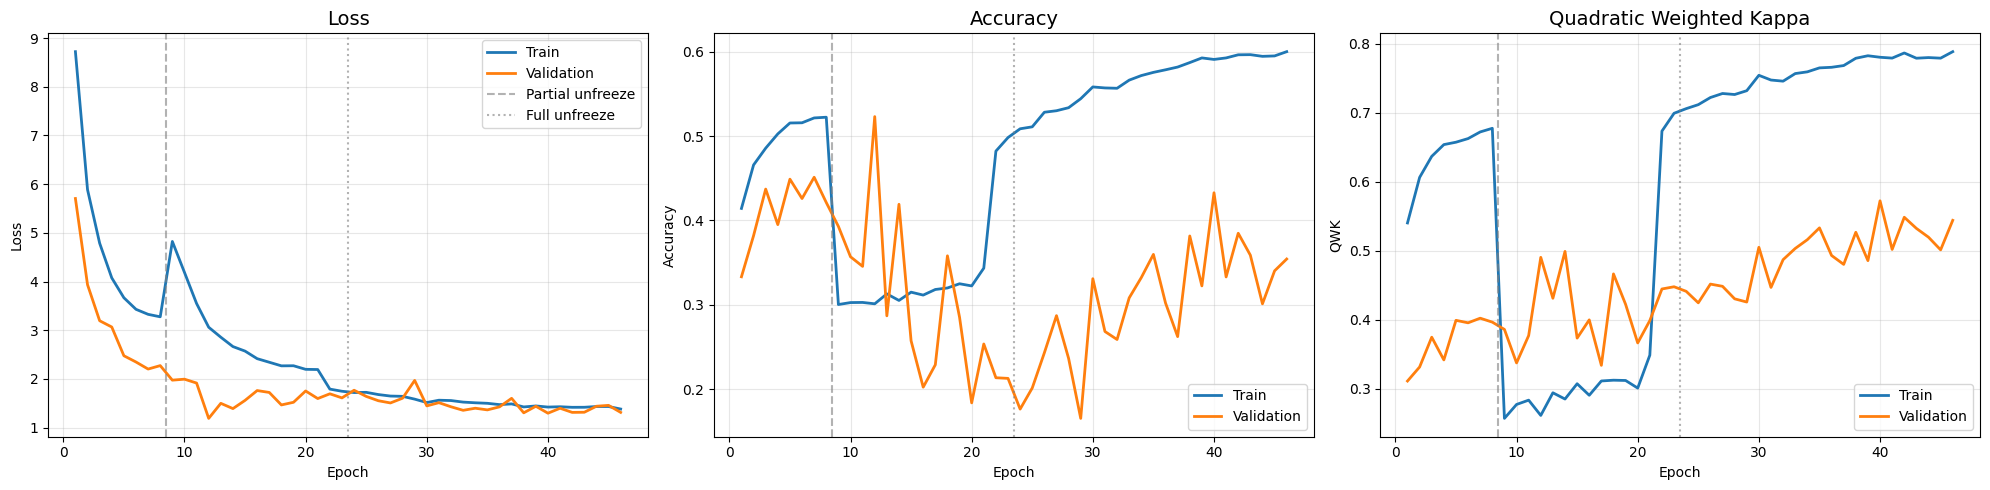

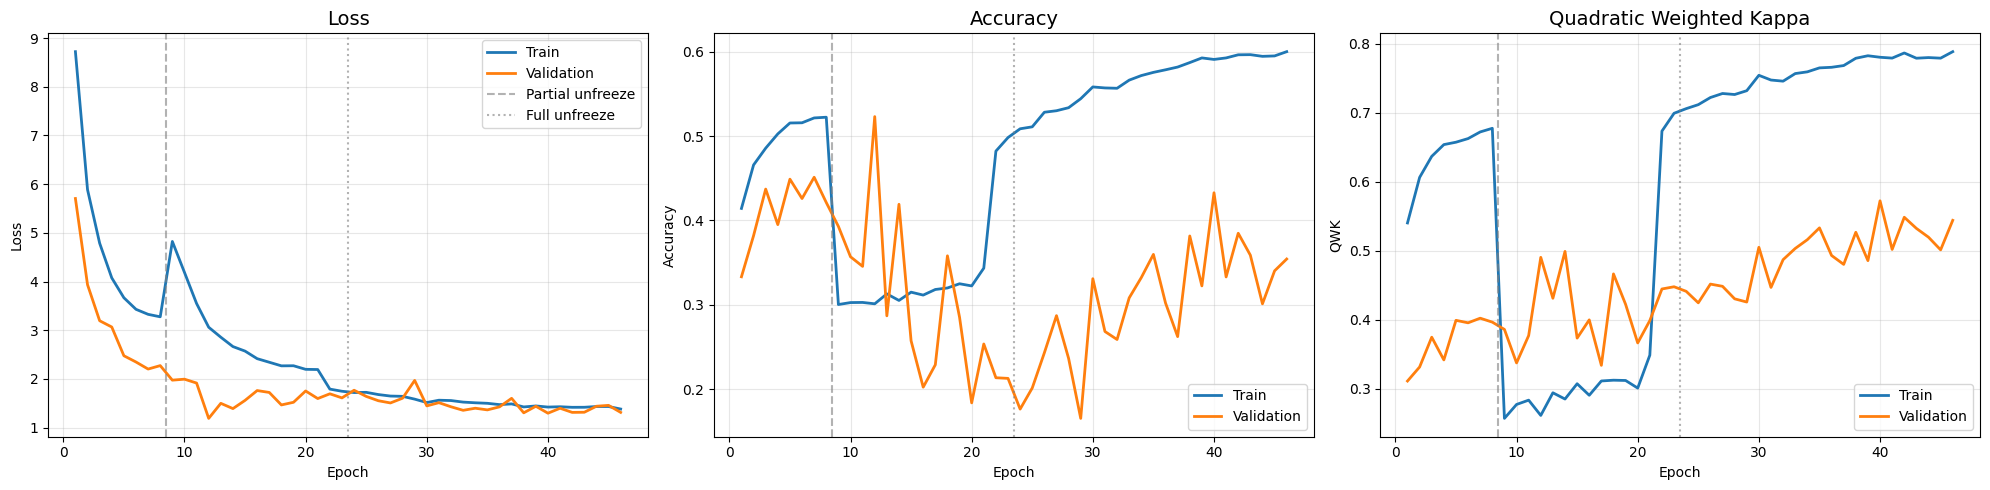

In [9]:
from src.evaluate import plot_training_curves

plot_training_curves(
    history,
    save_path=os.path.join(config.FIGURES_DIR, "training_curves.png"),
)

## 6. Quick Validation Check

In [10]:
from src.evaluate import compute_metrics, predict

trainer.load_best_checkpoint("phase3")

y_true, y_pred, y_proba = predict(model, loaders_phase23["valid"], device)
metrics = compute_metrics(y_true, y_pred, y_proba)

print(f"Validation QWK      : {metrics['qwk']:.4f}")
print(f"Validation Accuracy : {metrics['accuracy']:.4f}")
print(f"Validation ROC-AUC  : {metrics['roc_auc_weighted']:.4f}")
print(f"\n{metrics['classification_report_str']}")

2026-04-03 08:51:47 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase3.pth (epoch 19, QWK=0.5722)


Validation QWK      : 0.5723
Validation Accuracy : 0.4342
Validation ROC-AUC  : 0.8314

                  precision    recall  f1-score   support

           No_DR     0.9268    0.4251    0.5828      3844
            Mild     0.1023    0.6813    0.1779       386
        Moderate     0.5540    0.2852    0.3765       810
          Severe     0.2695    0.7200    0.3922       125
Proliferative_DR     0.3770    0.6765    0.4842       102

        accuracy                         0.4342      5267
       macro avg     0.4459    0.5576    0.4027      5267
    weighted avg     0.7828    0.4342    0.5150      5267



## 7. Save Test Split for Evaluation Notebook

In [11]:
test_csv_path = os.path.join(config.OUTPUTS_DIR, "test_split.csv")
test_df.to_csv(test_csv_path, index=False)
print(f"Test split saved to {test_csv_path} ({len(test_df)} images)")

Test split saved to /teamspace/studios/this_studio/diabetic_retinopathy/outputs/test_split.csv (5268 images)


## 8. ONNX Export

In [12]:
from src.export import export_to_onnx

onnx_path = export_to_onnx(
    checkpoint_path=os.path.join(config.CHECKPOINTS_DIR, "best_model_phase3.pth"),
)
print(f"\nONNX model exported to: {onnx_path}")

2026-04-03 08:53:37 | src.export | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase3.pth (epoch 18, QWK=0.5722471769600158)
2026-04-03 08:53:38 | src.export | INFO | ONNX validation passed (max diff: 7.15e-06)
2026-04-03 08:53:38 | src.export | INFO | ONNX model exported: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx (43.8 MB, opset 17)



ONNX model exported to: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx
